# Classification Experiments, Version 6
Yang Xiao (yx752)

## Step 0: Data and Frozen Features
This notebook reproduces the fixed submitted v6 configuration by default; optional parameter search is kept separate. A frozen GPT-2 checkpoint scores tokens locally; no checkpoint weights are updated and no external labels are used. Each passage is truncated to 511 tokens plus BOS. Features summarize log probabilities, entropy and token ranks. The extraction script builds these tables before running this notebook. Classification dependencies: numpy, pandas, scikit-learn, lightgbm and matplotlib. Extraction additionally needs torch, transformers and safetensors.

In [1]:
from pathlib import Path
import re,json,time,hashlib,os
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit,logit
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier
SEED=27
RUN_PARAMETER_SEARCH=False
FINAL_CONFIG={"family":"lgbm","view":"combined","leaves":31,"trees":400,"lr":.03,"l2":2}
FINAL_LM_WEIGHT=.75
paths=([Path(os.environ['V6_DATA_DIR'])] if os.environ.get('V6_DATA_DIR') else [Path('data'),Path('.'),Path('../cornell-tech-cs-5785-combined-2026-ai-vs-human-text')])
DATA=next((p for p in paths if (p/'train.csv').exists()),None)
if DATA is None:raise FileNotFoundError('Place the competition CSV files in data/.')
FEATURES=Path(os.environ.get('V6_LM_FEATURE_DIR','lm_features/gpt2'));OUT=Path('v6_search_results' if RUN_PARAMETER_SEARCH else 'v6_results');OUT.mkdir(exist_ok=True)
train=pd.read_csv(DATA/'train.csv');test=pd.read_csv(DATA/'test.csv');sample=pd.read_csv(DATA/'sample_submission.csv')
def load_lm(filename,frame):
    f=pd.read_csv(FEATURES/filename)
    meta=json.loads((FEATURES/(filename+'.json')).read_text())
    assert meta['model']=='openai-community/gpt2'
    assert meta['features']==[c for c in f.columns if c!='id']
    assert meta['input_sha256']==hashlib.sha256((DATA/filename).read_bytes()).hexdigest()
    assert f.id.tolist()==frame.id.tolist()
    return f.drop(columns='id').to_numpy()
lm=load_lm('train.csv',train);lm_test=load_lm('test.csv',test)
tr,va=train_test_split(np.arange(len(train)),test_size=2000,stratify=train.label,random_state=SEED)
y=train.label.to_numpy()[tr];yv=train.label.to_numpy()[va]
train.iloc[va][['id']].to_csv(OUT/'val_ids.csv',index=False)
print('Frozen model: openai-community/gpt2 | LM features:',lm.shape[1])
print('Training:',len(tr),'Development:',len(va),'Seed:',SEED)

Frozen model: openai-community/gpt2 | LM features: 23
Training: 8000 Development: 2000 Seed: 27


## Step 1: Style Features and v5 Baseline
Retain the 73 style features for baseline reproduction. The baseline uses a boosting model and an RBF SVM with 75% original/25% flat-format training weight. Component sigmoid mappings and final fusion reproduce v5. Baseline OOF arrays are recomputed for each run. Frozen LM features are label-independent, so computing them before the split does not fit any information to the development labels.

In [2]:
def extract_style_features(text):
    """Return measurable lexical, structural, repetition, and punctuation signals."""
    text = str(text)
    words = re.findall(r"\b[\w']+\b", text.lower())
    word_count = max(len(words), 1)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]
    paragraphs = [p for p in re.split(r"\n\s*\n", text.strip()) if p.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    paragraph_lengths = [len(re.findall(r"\b[\w']+\b", p)) for p in paragraphs]
    word_counts = pd.Series(words).value_counts()
    bigrams = list(zip(words, words[1:]))
    bigram_counts = pd.Series(bigrams).value_counts() if bigrams else pd.Series(dtype=int)
    normalized = text.lower()

    def repeat_fraction(counts, total):
        if total == 0 or len(counts) == 0:
            return 0.0
        return float((counts - 1).clip(lower=0).sum() / total)

    def mean(values):
        return float(np.mean(values)) if values else 0.0

    def std(values):
        return float(np.std(values)) if len(values) > 1 else 0.0

    # Candidate discourse templates; counts are normalized per 1,000 words below.
    template_patterns = {
        "not_just_but": r"\bnot just\b.{0,160}\bbut\b",
        "not_only_but_also": r"\bnot only\b.{0,160}\bbut also\b",
        "in_conclusion": r"\bin conclusion\b",
        "it_is_important_to_note": r"\bit is important to note\b",
        "moreover": r"\bmoreover\b",
        "furthermore": r"\bfurthermore\b",
    }
    features = {
        "log_word_count": np.log1p(len(words)),  # Log-scaled number of words.
        "log_character_count": np.log1p(len(text)),  # Log-scaled number of characters, including whitespace.
        "mean_word_length": mean([len(w) for w in words]),  # Average characters per token.
        "word_length_std": std([len(w) for w in words]),  # Variation in token lengths.
        "type_token_ratio": len(set(words)) / word_count,  # Unique words divided by total words; rough lexical diversity.
        "repeated_word_fraction": repeat_fraction(word_counts, len(words)),  # Fraction of word tokens beyond each word's first occurrence.
        "repeated_bigram_fraction": repeat_fraction(bigram_counts, len(bigrams)),  # Fraction of adjacent word-pairs beyond each pair's first occurrence.
        "sentence_count": np.log1p(len(sentences)),  # Log-scaled count of sentence-like spans.
        "mean_sentence_length": mean(sentence_lengths),  # Average words per sentence-like span.
        "sentence_length_std": std(sentence_lengths),  # Spread of sentence lengths.
        "sentence_length_cv": std(sentence_lengths) / max(mean(sentence_lengths), 1.0),  # Sentence-length spread relative to its mean.
        "paragraph_count": np.log1p(len(paragraphs)),  # Log-scaled count of blocks separated by blank lines.
        "mean_paragraph_length": mean(paragraph_lengths),  # Average words per paragraph block.
        "paragraph_length_std": std(paragraph_lengths),  # Spread of paragraph word counts.
        "repeated_sentence_fraction": (len(sentences) - len(set(s.strip().lower() for s in sentences))) / max(len(sentences), 1),  # Share of sentence-like spans duplicated after lowercasing.
        "exclamation_per_100_words": 100 * text.count("!") / word_count,  # Exclamation marks per 100 words.
        "question_per_100_words": 100 * text.count("?") / word_count,  # Question marks per 100 words.
        "comma_per_100_words": 100 * text.count(",") / word_count,  # Commas per 100 words.
        "semicolon_per_100_words": 100 * text.count(";") / word_count,  # Semicolons per 100 words.
        "colon_per_100_words": 100 * text.count(":") / word_count,  # Colons per 100 words.
        "dash_per_100_words": 100 * (text.count("—") + text.count("–")) / word_count,  # Em/en dashes per 100 words.
        "ellipsis_per_100_words": 100 * (text.count("...") + text.count("…")) / word_count,  # Three-dot or single-character ellipses per 100 words.
        "digit_character_fraction": sum(ch.isdigit() for ch in text) / max(len(text), 1),  # Fraction of all characters that are digits.
        "uppercase_character_fraction": sum(ch.isupper() for ch in text) / max(sum(ch.isalpha() for ch in text), 1),  # Fraction of letters that are uppercase.
        "contraction_per_100_words": 100 * len(re.findall(r"\b\w+['’](?:t|re|ve|ll|d|m)\b", normalized)) / word_count,  # Common English contractions per 100 words.
    }
    for name, pattern in template_patterns.items():
        # Frequency of each hypothesized phrase pattern per 1,000 words.
        features[f"template_{name}_per_1000_words"] = 1000 * len(re.findall(pattern, normalized, flags=re.DOTALL)) / word_count
    return features

def expanded_features(text):
    features=extract_style_features(text)
    words=re.findall(r"[a-z]+(?:['’][a-z]+)?",text.lower())
    n=max(len(words),1);nc=max(len(text),1)
    counts=Counter(words)
    values=np.asarray(list(counts.values()),dtype=float)
    lengths=np.asarray([len(w) for w in words],dtype=float)
    sentence_text=[s for s in re.split(r'[.!?]+(?:["\'”’)]*)\s+|\n+',text) if s.strip()]
    sentence_lengths=np.asarray([len(re.findall(r'\b\w+\b',s)) for s in sentence_text],dtype=float)
    for name,array in [('token_length',lengths),('sentence_length',sentence_lengths)]:
        for q in [10,25,50,75,90]:features[f'{name}_q{q}']=float(np.percentile(array,q)) if len(array) else 0.
    features['hapax_ratio']=float(np.sum(values==1)/max(len(values),1))
    features['dislegomena_ratio']=float(np.sum(values==2)/max(len(values),1))
    features['token_entropy']=float(-np.sum((values/n)*np.log(values/n))) if len(values) else 0.
    features['top_token_fraction']=float(values.max()/n) if len(values) else 0.
    features['long_word_fraction']=float(np.mean(lengths>=8)) if len(lengths) else 0.
    features['short_word_fraction']=float(np.mean(lengths<=3)) if len(lengths) else 0.
    groups={
        'first_person':'i me my mine we us our ours',
        'second_person':'you your yours yourself yourselves',
        'third_person':'he him his she her hers they them their theirs',
        'articles':'a an the',
        'prepositions':'of in on at for from to with by about into over under between through',
        'conjunctions':'and or but so because although while whereas if unless since',
        'modals':'can could may might must shall should will would',
        'negations':"no not never neither nor cannot don't doesn't didn't isn't aren't wasn't weren't",
        'demonstratives':'this that these those',
        'be_forms':'am is are was were be been being',
        'have_forms':'have has had having',
    }
    for name,group in groups.items():features[name+'_fraction']=sum(counts[w] for w in group.split())/n
    for char,name in [('"','straight_quote'),("'",'apostrophe'),('(','open_parenthesis'),(')','close_parenthesis'),('[','bracket'),('/','slash'),('-','hyphen'),('%','percent'),(chr(10),'newline')]:
        features[name+'_per_100_words']=100*text.count(char)/n
    features['non_ascii_fraction']=sum(ord(c)>127 for c in text)/nc
    features['whitespace_fraction']=sum(c.isspace() for c in text)/nc
    features['double_space_fraction']=len(re.findall(r' {2,}',text))/nc
    features['sentence_short_fraction']=float(np.mean(sentence_lengths<8)) if len(sentence_lengths) else 0.
    features['sentence_long_fraction']=float(np.mean(sentence_lengths>30)) if len(sentence_lengths) else 0.
    features['list_line_fraction']=len(re.findall(r'(?m)^\s*(?:[-*•]|\d+[.)])\s+',text))/max(len(text.splitlines()),1)
    return features

def canonicalize(text):
    return re.sub(r'\s+',' ',str(text)).translate(str.maketrans({'’':"'",'‘':"'",'“':'"','”':'"','—':'-','–':'-','…':'...'})).strip()

In [3]:
z=pd.DataFrame([expanded_features(str(t)) for t in train.text]).to_numpy()
zf=pd.DataFrame([expanded_features(canonicalize(t)) for t in train.text]).to_numpy()
ztest=pd.DataFrame([expanded_features(str(t)) for t in test.text]).to_numpy()
assert z.shape[1]==73 and np.isfinite(z).all() and np.isfinite(lm).all()
def base_model(j):
    if j==0:return HistGradientBoostingClassifier(max_iter=250,max_leaf_nodes=31,l2_regularization=1,learning_rate=.06,early_stopping=False,random_state=SEED)
    return make_pipeline(StandardScaler(),SVC(C=10,gamma='scale',cache_size=512))
def fit_base(j,a,b,labels):
    model=base_model(j);weights=np.concatenate([np.full(len(labels),.75),np.full(len(labels),.25)])
    kw={'svc__sample_weight':weights} if j==1 else {'sample_weight':weights}
    return model.fit(np.concatenate([a,b]),np.tile(labels,2),**kw)
def base_oof(indices,labels):
    output=np.zeros((2,len(indices),2))
    for a,b in StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(indices,labels):
        for j in [0,1]:
            m=fit_base(j,z[indices[a]],zf[indices[a]],labels[a])
            for v,matrix in enumerate([z,zf]):output[v,b,j]=m.decision_function(matrix[indices[b]])
    return output
def base_mappings(raw,labels):
    maps={};weights=np.concatenate([np.full(len(labels),.75),np.full(len(labels),.25)])
    for j in [0,1]:maps[j]=LogisticRegression(C=10,max_iter=1000,random_state=SEED).fit(raw[:,:,j].reshape(-1,1),np.tile(labels,2),sample_weight=weights)
    fusion=.75*maps[0].decision_function(raw[:,:,0].reshape(-1,1))+.25*maps[1].decision_function(raw[:,:,1].reshape(-1,1))
    meta=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(fusion.reshape(-1,1),np.tile(labels,2))
    return maps,meta
def base_logits(raw,maps,meta):
    fusion=.75*maps[0].decision_function(raw[:,:,0].reshape(-1,1))+.25*maps[1].decision_function(raw[:,:,1].reshape(-1,1))
    return meta.decision_function(fusion.reshape(-1,1)).reshape(raw.shape[:2])
# Recompute baseline folds to avoid depending on a stale optional cache.
base_raw=base_oof(tr,y)
base_maps,base_meta=base_mappings(base_raw,y)
baseline_oof=base_logits(base_raw,base_maps,base_meta)[0]
assert np.isfinite(baseline_oof).all()
print('Baseline ordinary OOF AUROC:',roc_auc_score(y,baseline_oof))

Baseline ordinary OOF AUROC: 0.9963936250000001


## Step 2: Frozen-Feature Classifiers
Compare LM-only LightGBM, LM+style LightGBM and LM+style histogram boosting on three fixed training-only folds. New feature classifiers use original passages only. Search a small predeclared tree grid. Component calibration and fusion are fitted from training OOF scores; their OOF values are selection scores, not an unbiased final estimate.

For final reproduction, RUN_PARAMETER_SEARCH=False fixes candidate settings to 31 leaves, 400 trees, learning rate 0.03, L2=2 and LM-branch weight 0.75. The 73-feature v5 branch and its internal settings remain unchanged. A new search result never silently replaces this recorded choice in the default mode.

In [4]:
configs=[]
for leaves in [15,31]:configs.append({'family':'lgbm','view':'lm','leaves':leaves,'trees':400,'lr':.03,'l2':2})
for leaves in [7,15,31]:configs.append({'family':'lgbm','view':'combined','leaves':leaves,'trees':400,'lr':.03,'l2':2})
configs.append({'family':'lgbm','view':'combined','leaves':15,'trees':800,'lr':.02,'l2':5})
configs.append({'family':'hgb','view':'combined','leaves':31,'trees':250,'lr':.06,'l2':1})
views={'lm':lm,'combined':np.column_stack([lm,z])}
test_views={'lm':lm_test,'combined':np.column_stack([lm_test,ztest])}
def new_model(c):
    if c['family']=='lgbm':return LGBMClassifier(n_estimators=c['trees'],learning_rate=c['lr'],num_leaves=c['leaves'],min_child_samples=30,reg_lambda=c['l2'],colsample_bytree=.8,subsample=.8,subsample_freq=1,n_jobs=4,random_state=SEED,verbosity=-1)
    return HistGradientBoostingClassifier(max_iter=c['trees'],learning_rate=c['lr'],max_leaf_nodes=c['leaves'],l2_regularization=c['l2'],early_stopping=False,random_state=SEED)
def new_score(model,matrix):
    if hasattr(model,'decision_function'):return model.decision_function(matrix)
    return logit(np.clip(model.predict_proba(matrix)[:,1],1e-12,1-1e-12))
folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(tr,y))
oof=np.zeros((len(tr),len(configs)));rows=[]
recorded_id=configs.index(FINAL_CONFIG)
active_ids=list(range(len(configs))) if RUN_PARAMETER_SEARCH else [recorded_id]
for j in active_ids:
    c=configs[j]
    matrix=views[c['view']];start=time.perf_counter()
    for a,b in folds:
        m=new_model(c).fit(matrix[tr[a]],y[a]);oof[b,j]=new_score(m,matrix[tr[b]])
    rows.append({'candidate':j,**c,'ordinary_oof_auroc':roc_auc_score(y,oof[:,j]),'seconds':time.perf_counter()-start})
    print(j,c,'OOF:',rows[-1]['ordinary_oof_auroc'],flush=True)
search=pd.DataFrame(rows).sort_values('ordinary_oof_auroc',ascending=False)
search.to_csv(OUT/'search.csv',index=False);np.save(OUT/('new_oof.npy' if RUN_PARAMETER_SEARCH else 'fixed_oof.npy'),oof)
new_maps={j:LogisticRegression(C=10,max_iter=1000,random_state=SEED).fit(oof[:,j].reshape(-1,1),y) for j in active_ids}
blend_rows=[]
for j in active_ids:
    new_logits=new_maps[j].decision_function(oof[:,j].reshape(-1,1))
    for weight in ([0,.25,.5,.75,1] if RUN_PARAMETER_SEARCH else [FINAL_LM_WEIGHT]):
        values=(1-weight)*baseline_oof+weight*new_logits
        blend_rows.append({'candidate':j,'new_weight':weight,'ordinary_oof_auroc':roc_auc_score(y,values)})
blends=pd.DataFrame(blend_rows).sort_values(['ordinary_oof_auroc','new_weight','candidate'],ascending=[False,True,True])
if RUN_PARAMETER_SEARCH:
    chosen_id=int(blends.iloc[0].candidate);weight=float(blends.iloc[0].new_weight)
else:
    chosen_id=recorded_id;weight=FINAL_LM_WEIGHT
chosen=configs[chosen_id]
if not RUN_PARAMETER_SEARCH:
    assert chosen==FINAL_CONFIG and weight==FINAL_LM_WEIGHT
print('Run mode:', 'parameter search' if RUN_PARAMETER_SEARCH else 'fixed submitted configuration')
training_scores=(1-weight)*baseline_oof+weight*new_maps[chosen_id].decision_function(oof[:,chosen_id].reshape(-1,1))
meta_cal=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(training_scores.reshape(-1,1),y)
print(blends.head(10).to_string(index=False));print('Selected:',chosen,'LM branch weight:',weight)
blends.to_csv(OUT/'blend_search.csv',index=False)

4 {'family': 'lgbm', 'view': 'combined', 'leaves': 31, 'trees': 400, 'lr': 0.03, 'l2': 2} OOF: 0.999152
Run mode: fixed submitted configuration
 candidate  new_weight  ordinary_oof_auroc
         4        0.75            0.999188
Selected: {'family': 'lgbm', 'view': 'combined', 'leaves': 31, 'trees': 400, 'lr': 0.03, 'l2': 2} LM branch weight: 0.75


## Step 3: Fixed Development Evaluation
Fit the chosen branch on the 8,000 training rows and apply the preselected fusion to the same 2,000 development rows. No development labels choose tree settings or weights. This partition has nevertheless been inspected in earlier iterations, so it remains a development comparison rather than an independent final test.

         model  development_auroc
   v5 baseline           0.998104
 Frozen branch           0.999448
Selected blend           0.999590


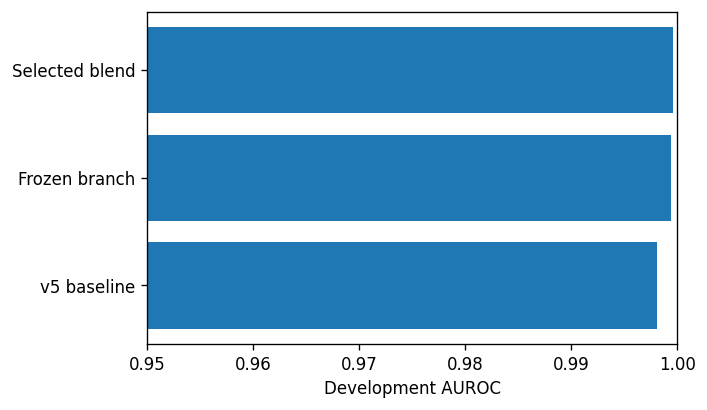

In [5]:
baseline_dev_raw=np.zeros((1,len(va),2))
for j in [0,1]:
    m=fit_base(j,z[tr],zf[tr],y);baseline_dev_raw[0,:,j]=m.decision_function(z[va])
baseline_dev=base_logits(baseline_dev_raw,base_maps,base_meta)[0]
m=new_model(chosen).fit(views[chosen['view']][tr],y)
new_dev=new_maps[chosen_id].decision_function(new_score(m,views[chosen['view']][va]).reshape(-1,1))
dev_score=(1-weight)*baseline_dev+weight*new_dev
probability=meta_cal.predict_proba(dev_score.reshape(-1,1))[:,1]
comparison=pd.DataFrame({'model':['v5 baseline','Frozen branch','Selected blend'],'development_auroc':[roc_auc_score(yv,baseline_dev),roc_auc_score(yv,new_dev),roc_auc_score(yv,dev_score)]})
print(comparison.to_string(index=False));comparison.to_csv(OUT/'development_comparison.csv',index=False)
pd.DataFrame({'id':train.id.to_numpy()[va],'label':yv,'probability':probability}).to_csv(OUT/'validation_predictions.csv',index=False)
summary={'seed':SEED,'run_mode':'parameter_search' if RUN_PARAMETER_SEARCH else 'fixed_final','software_versions':{name:__import__(name).__version__ for name in ['numpy','pandas','scipy','sklearn','lightgbm']},'python_version':__import__('platform').python_version(),'frozen_model':'openai-community/gpt2','chosen':chosen,'new_weight':weight,'selection_oof_auroc':float(blends.iloc[0].ordinary_oof_auroc),'development':comparison.to_dict(orient='records'),'probability_development_auroc':roc_auc_score(yv,probability),'lm_input_hashes':{name:hashlib.sha256((FEATURES/name).read_bytes()).hexdigest() for name in ['train.csv','test.csv']}}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
fig,ax=plt.subplots(figsize=(6,3.5));ax.barh(comparison.model,comparison.development_auroc);ax.set_xlim(.95,1);ax.set_xlabel('Development AUROC');fig.tight_layout();plt.show()

## Step 4: Full-Data Refit
Keep branch settings and weights fixed. Regenerate training-only OOF scores on all 10,000 labeled rows to fit calibration, then refit selected components on all labeled rows. Frozen features remain unchanged and require no competition labels. Test IDs follow the sample submission order.

In [6]:
yfull=train.label.to_numpy();all_indices=np.arange(len(train))
full_baseline_oof=base_oof(all_indices,yfull)
full_base_maps,full_base_meta=base_mappings(full_baseline_oof,yfull)
full_base_logits=base_logits(full_baseline_oof,full_base_maps,full_base_meta)[0]
full_new_oof=np.zeros(len(train));matrix=views[chosen['view']]
for a,b in StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(all_indices,yfull):
    m=new_model(chosen).fit(matrix[a],yfull[a]);full_new_oof[b]=new_score(m,matrix[b])
final_new_map=LogisticRegression(C=10,max_iter=1000,random_state=SEED).fit(full_new_oof.reshape(-1,1),yfull)
full_scores=(1-weight)*full_base_logits+weight*final_new_map.decision_function(full_new_oof.reshape(-1,1))
final_meta=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(full_scores.reshape(-1,1),yfull)
base_test_raw=np.zeros((1,len(test),2))
for j in [0,1]:
    m=fit_base(j,z,zf,yfull);base_test_raw[0,:,j]=m.decision_function(ztest)
base_test_logits=base_logits(base_test_raw,full_base_maps,full_base_meta)[0]
m=new_model(chosen).fit(matrix,yfull)
new_test_logits=final_new_map.decision_function(new_score(m,test_views[chosen['view']]).reshape(-1,1))
test_score=(1-weight)*base_test_logits+weight*new_test_logits
submission=pd.DataFrame({'id':test.id,'label':final_meta.predict_proba(test_score.reshape(-1,1))[:,1]})
submission=submission.set_index('id').loc[sample.id].reset_index()
assert list(submission)==['id','label'] and len(submission)==3000 and submission.id.is_unique
assert submission.id.tolist()==sample.id.tolist() and set(submission.id)==set(test.id)
assert np.isfinite(submission.label).all() and submission.label.between(0,1).all()
submission.to_csv(OUT/'submission_yx752_v6.csv',index=False)
print('Saved 3,000 test probabilities to',OUT/'submission_yx752_v6.csv')

Saved 3,000 test probabilities to v6_results\submission_yx752_v6.csv


## Results
Frozen token statistics provide a different signal from the style baseline. LM-only models reached approximately 0.9867 ordinary training OOF AUROC; adding the 73 style features raised the best single branch to 0.999152. The selected branch uses LightGBM with 31 leaves, 400 trees, learning rate 0.03 and L2=2. Selection gives it 75% weight and retains 25% v5, with combined training OOF AUROC 0.999188.

On the shared development partition, v5 has AUROC 0.998104, the frozen-feature branch 0.999448, and the selected blend 0.999590. This supports complementary information in the frozen statistics on this split, but does not establish a public or private leaderboard score. The checkpoint stays frozen, its features use no competition labels, and all classifier/calibration labels come from train.csv. No outside labeled proxy or test pseudo-labels are used. The development set has been inspected across iterations and OOF labels are reused for calibration and selection. Final predictions use all 10,000 labeled rows after the approach is fixed.